In [1]:
import pandas as pd
df = pd.read_csv("protein_fluorescence.csv")
df.head()


   time/s  counts
0   0.042    1186
1   0.083    1163
2   0.125    1112
3   0.167    1098
4   0.209    1050

In [2]:
x=df["time/s"]
y=df["counts"]

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline

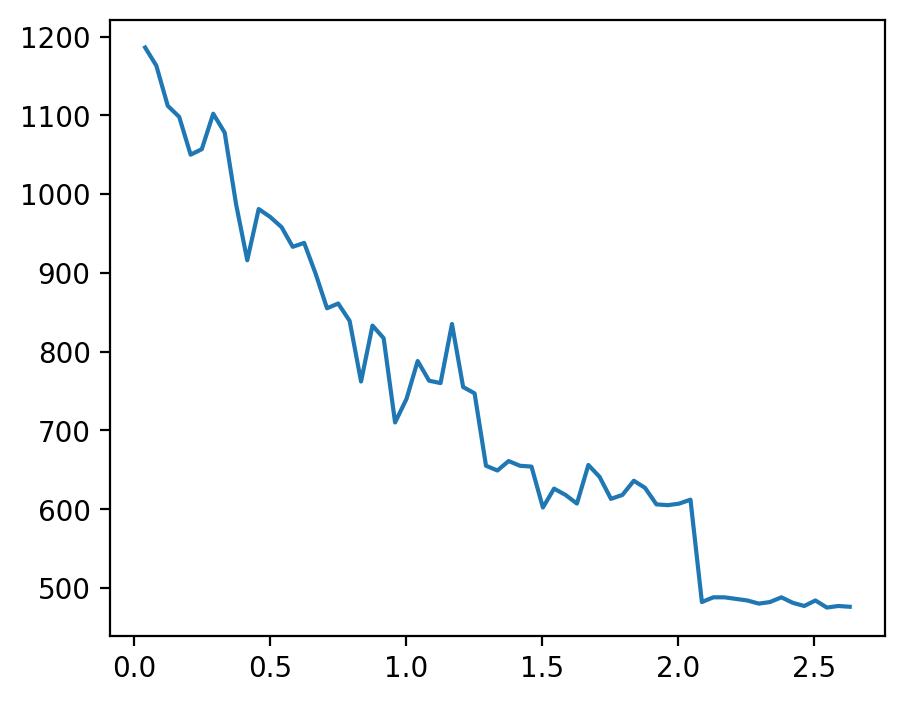

In [4]:
fig = plt.figure(figsize=(5,4), dpi=200)
plt.plot(x, y)
#plt.plot(x, linear(x, slope, intercept), 'r', label='Fitted line') 

In [5]:
from scipy.optimize import curve_fit
import numpy as np
def exponential(x, a, b, c):
    return a*np.exp(-b*x)+c
parameters, covariant_matrix = curve_fit(exponential, x, y, p0=(1200, 0.5, 200))
a_fitted = parameters[0] #slope parameter is parameter #0
b_fitted = parameters[1] #exponential parameter is parameter #1
c_fitted = parameters[2] #intercept parameter is parameter #2

parameter_uncertainties = np.sqrt(covariant_matrix.diagonal())
scalar_error = parameter_uncertainties[0]
decay_constant_error = parameter_uncertainties[1]
background_error= parameter_uncertainties[2]

print('Intercept: {:.0f} Error on intercept: {:.0f}'.format(a_fitted, scalar_error))
print('Decay constant: {:.2f} Error on decay constant: {:.2f}'.format(b_fitted, decay_constant_error))
print('Background: {:.2f} Error on background: {:.2f}'.format(c_fitted, background_error))


Intercept: 926 Error on intercept: 48
Decay constant: 0.58 Error on decay constant: 0.07
Background: 264.01 Error on background: 56.68


In [6]:
print(a_fitted,b_fitted,c_fitted)

926.4196002882584 0.5807632182236819 264.0078360125187


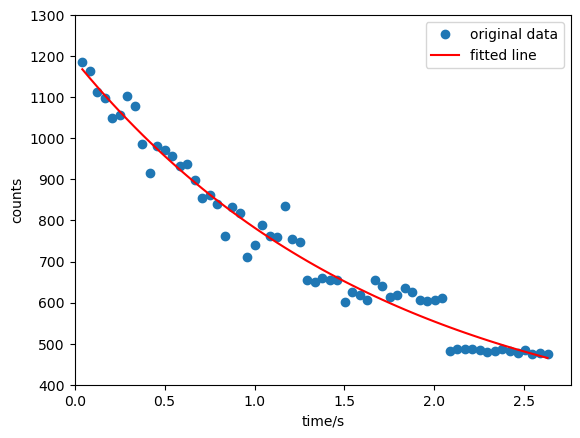

In [7]:
import matplotlib.pyplot as plt
plt.plot(x, y, "o", label="original data")
plt.plot(x, a_fitted*np.exp(-1*b_fitted*x)+ c_fitted, "r", label="fitted line")
plt.xlabel("time/s")
plt.ylabel("counts")
plt.xlim(left = 0)
plt.ylim(bottom = 400, top = 1300)
plt.legend()
plt.show()

In [8]:
df["log counts corrected"] = np.log(df["counts"].values - c_fitted)
df.head()


   time/s  counts  log counts corrected
0   0.042    1186              6.826537
1   0.083    1163              6.801274
2   0.125    1112              6.742871
3   0.167    1098              6.726224
4   0.209    1050              6.666947

In [9]:
X=df["time/s"]
Y=df["log counts corrected"]

In [11]:
def linear(x, a, b):
    return a * x + b

In [16]:
parameters, covariant_matrix = curve_fit(linear, X, Y, absolute_sigma=True)
slope = parameters[0] #extract slope, it is parameter #0
intercept = parameters[1] #extract intercept, it is parameter #1

In [19]:
parameter_uncertainties = np.sqrt(covariant_matrix.diagonal())
slope_error = parameter_uncertainties[0]
intercept_error = parameter_uncertainties[1]

print('Intercept: {:.5f} Error on intercept: {:.5f}'.format(intercept, intercept_error))
print('Slope: {:.2f} Error on slope: {:.2f}'.format(slope, slope_error))

Intercept: 6.83448 Error on intercept: 0.25500
Slope: -0.59 Error on slope: 0.17


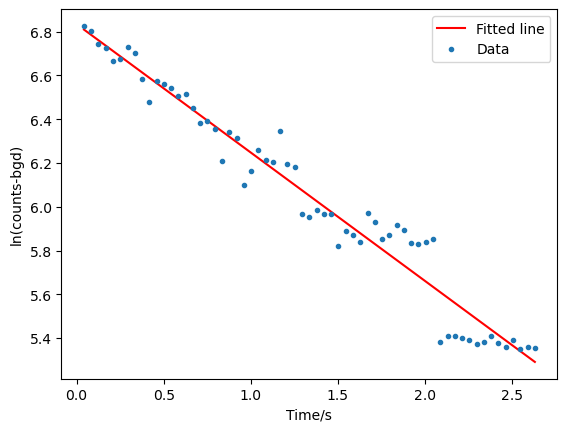

In [24]:
plt.errorbar(X, Y, label='Data', fmt='.', capsize=5)
plt.plot(X, linear(X, slope, intercept), 'r', label='Fitted line') # note: we can write any formula into this plotting function
plt.xlabel('Time/s')
plt.ylabel('ln(counts-bgd)')
plt.legend()
plt.show()